# Spoken Grammar Scoring Engine
SHL Hiring Assessment 2026, Anuj Dev Singh

The task: given a 45-60 s recording of someone speaking English, predict the grammar score (0 to 5, in steps of
0.5) that a human rater gave using SHL's rubric. There are 769 scored training clips and 216 test clips, and the
metrics are RMSE and Pearson correlation.

A rater listens to the speech, so I score the audio directly and use the transcript as a second source of
information. Five models each predict a score:
1. Frozen Whisper-large-v3 and WavLM-large encoders turn each clip into one vector, and a Ridge regression maps it
   to a score.
2. WavLM-large fine-tuned on the scores.
3. Qwen2-Audio-7B fine-tuned with QLoRA and a regression head.
4. An adapter grader: small adapters and one Transformer layer on frozen Whisper frames, trained with pseudo-labels
   that cannot leak into validation.
5. Fluency and grammar features from Whisper transcripts.

A non-negative linear stack, fitted on out-of-fold predictions, combines them. The test set has no invalid
recordings, so the models learn from scores 1-5, and a simple rule keeps invalid-looking clips near 0.

Kaggle allows two final submissions, and I picked these:
- e013 uses all five models and has the best cross-validation score.
- e009 leaves out the adapter and has the best public leaderboard score.

Section 6 explains why I kept both. Every number in this notebook comes from the same fixed CV folds.

Contents: 1 Data, 2 Preprocessing, 3 Models and stack, 4 Results (training RMSE, CV RMSE, Pearson),
5 Visualisations, 6 CV vs leaderboard, 7 Error analysis and what failed, 8 Reproduce.

The competition data is for competition use only, so this notebook only shows aggregate numbers and plots. It
never prints audio, transcripts or per-file rows.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from cv import DATA, get_folds, pearson, rmse  # noqa: E402

CACHE = ROOT / "cache"
FINAL, ALT = "e013", "e009"  # the two final submissions, written by src/final.py
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
BLUE, ORANGE, GREY, GREEN = "#2f6db5", "#e07b39", "#8c8c8c", "#3a9a5b"

## 1. Data
The labels lean towards higher scores. 37 clips are scored 0, which is below the rubric's lowest level of 1. When I
checked them with Whisper they turned out to be invalid recordings: high no-speech probability, low ASR confidence,
and often not clearly English. The test set has none of these; a detector that catches all 37 in train flags no
test clip.

The test clips are also shorter (median 45 s against 60 s) and a bit quieter, and they differ in other ways too:
a classifier can tell train clips from test clips with AUC 0.84 (more on this in section 6).

train clips 769, test clips 216
label mean 3.313, std 1.238, clips labelled 0: 37


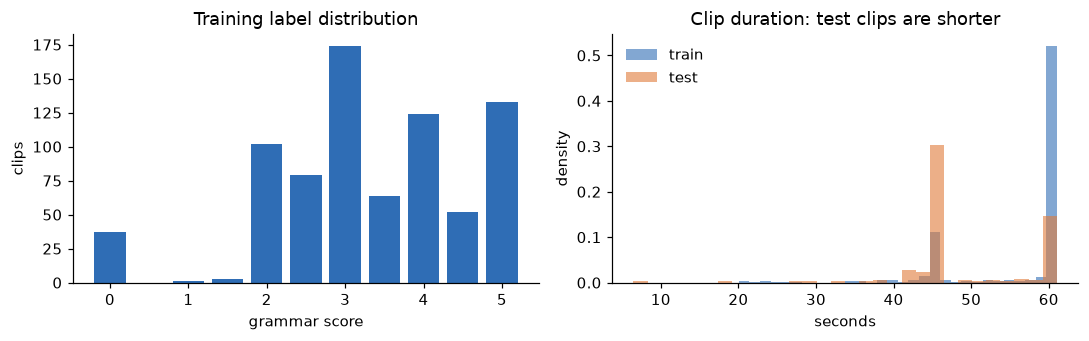

In [2]:
train = pd.read_csv(DATA / "train.csv")
audit = pd.read_csv(CACHE / "audit_audio.csv")
y_all = train.label
print(f"train clips {len(train)}, test clips {len(pd.read_csv(DATA / 'test.csv'))}")
print(f"label mean {y_all.mean():.3f}, std {y_all.std(ddof=0):.3f}, clips labelled 0: {(y_all == 0).sum()}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
vc = y_all.value_counts().sort_index()
ax[0].bar(vc.index, vc.values, width=0.4, color=BLUE)
ax[0].set(title="Training label distribution", xlabel="grammar score", ylabel="clips")
for s, c in [("train", BLUE), ("test", ORANGE)]:
    ax[1].hist(audit[audit.split == s].duration, bins=30, alpha=0.6, color=c, label=s, density=True)
ax[1].set(title="Clip duration: test clips are shorter", xlabel="seconds", ylabel="density")
ax[1].legend(frameon=False)
plt.tight_layout()
plt.show()

## 2. Preprocessing
All files are already 16 kHz mono 16-bit, with no clipping and no duplicates, so nothing needs resampling. I
normalise loudness (RMS) to about -20 dBFS so the quieter test clips match train; I use RMS rather than peak so a
single click cannot set the scale. I do not trim silence, because pauses and hesitations are part of what the
rater hears. Whisper's encoder reads at most 30 s, so clips are cut into 30 s windows, and for the frozen vectors
the windows are averaged by length with padding frames ignored. Because test clips are shorter, every transcript
count is per second or per word, and raw duration and word counts are left out.

## 3. Models and stack
| Model | What it captures | How it is trained |
|---|---|---|
| Frozen audio | Whisper-large-v3 encoder + WavLM-large: mean and std over time of every layer, averaged per model | Standardise -> RidgeCV |
| Fine-tuned WavLM | WavLM-large trained end to end on the scores: 20 s random crops, 8 epochs, learned layer weights and a small MLP head | 5 fold models |
| Fine-tuned audio LLM | Qwen2-Audio-7B in 4-bit, LoRA rank 16 on the language model, a regression head on the last prompt token. Rubric prompt + 30 s of audio, 3 epochs | 5 fold models |
| Adapter grader (e013 only) | Frozen Whisper-large-v3 frames from layers 16/22/27/32, every 80 ms. Per-layer adapters (LayerNorm, Linear 1280 to 128, GELU, Linear), one Transformer layer, mean + std pooling, MLP head; about 1M trainable parameters. 20 s crops with masked spans, 15 epochs, 3 seeds, plus pseudo-labels | 5 fold models x 3 seeds |
| Transcript | faster-whisper large-v3, prompted to keep "um" and restarts. 42 features: pauses, speech rate, fillers, ASR confidence, vocabulary variety, LanguageTool errors per 100 words, GPT-2 likelihood, syntax depth, clauses | Standardise -> RidgeCV |
| Stack | how much to trust each model | Non-negative linear regression on out-of-fold predictions, clipped to [0, 5] |

Why an adapter grader? The frozen Ridge model averages over time before it learns anything, so a short event
like a broken sentence gets averaged away. The adapter looks at the frame-level features first and pools
afterwards. It was the best single model in the winning Speak & Improve 2025 system, and it is my best single
model here too.

The pseudo-labels are built so they cannot leak. For fold k, a teacher made only from models that never saw fold
k's labels scores fold k's clips and the 216 test clips. The adapter then trains on the real labels of the other
folds plus these pseudo-labels at half weight, and it is scored on fold k's real labels. That way it gets to learn
from recordings like the test ones without seeing any label it is later judged on.

For e013, the Ridge models and the stack train on the 732 clips scored 1-5, since the test set has no invalid
clips. A separate frozen model trained on all clips acts as a detector: if it predicts below 1.0, that low score
is kept. In CV this catches all 37 label-0 clips and no test clip.

For validation I use stratified 5-fold CV with the folds fixed once and reused everywhere. Fine-tuning only ran on
repeat 0 (one fine-tuned model costs 1-4 GPU-hours per fold), so every comparison uses repeat 0. The stack is
cross-validated too: its weights are fitted on 4 folds and scored on the fifth. I only added something if it
improved at least 4 of the 5 folds and the bootstrap 95% interval of the gain was above 0.

Here is what the transcript features look for, on a made-up sentence (not competition data):

In [3]:
import spacy  # noqa: E402

nlp = spacy.load("en_core_web_md")
doc = nlp("Yesterday he go to the market and, um, I buyed a apple because it was cheap.")
print("tokens:", [t.text for t in doc])
print("he + base-form verb (agreement error):",
      [(t.text, t.head.text) for t in doc if t.lower_ == "he" and t.dep_ == "nsubj" and t.head.tag_ == "VBP"])
print("'a' before a vowel sound:", [(a.text, b.text) for a, b in zip(doc[:-1], doc[1:]) if a.lower_ == "a" and b.text[0] in "aeiou"])
print("subordinate clauses:", [t.text for t in doc if t.dep_ in {"advcl", "ccomp", "relcl", "mark"}])

tokens: ['Yesterday', 'he', 'go', 'to', 'the', 'market', 'and', ',', 'um', ',', 'I', 'buyed', 'a', 'apple', 'because', 'it', 'was', 'cheap', '.']
he + base-form verb (agreement error): [('he', 'go')]
'a' before a vowel sound: [('a', 'apple')]
subordinate clauses: ['because', 'was']


## 4. Results
Training RMSE (in-sample) means refitting every model that can be refit (the Ridge models and the stack) on all
769 clips and scoring those same clips, so it is optimistic by design. CV RMSE and Pearson come from predicting
each clip with a model that never saw it, which is the fair estimate.

The fine-tuned and adapter models have no version trained on all the data; their test prediction is the average of
the 5 fold models. So when computing the stack's training RMSE, their out-of-fold predictions stand in. In e013 the
adapter carries most of the stack weight, which is why its in-sample number ends up close to its CV number. That
is expected and not a leak.

The rows for individual models are scored on the 732 clips rated 1-5, because that is what the test set looks
like. The stack line also gives the result on all 769 clips.

In [4]:
def results(exp):
    d = np.load(CACHE / f"final_{exp}.npz", allow_pickle=True)
    s = json.load(open(CACHE / f"final_{exp}.json"))
    t = pd.read_csv(CACHE / f"final_{exp}_table.csv").set_index("model")
    y, P, st, nz = d["y"], d["P"], d["stack_oof"], d["y"] > 0
    rows = [dict(model=n, weight=round(s["weights"][n], 3), cv_rmse_1to5=rmse(y[nz], P[nz, i]),
                 cv_pearson_1to5=pearson(y[nz], P[nz, i]), train_rmse=t.loc[n, "train_rmse"])
            for i, n in enumerate(d["names"])]
    rows.append(dict(model="STACK", weight=np.nan, cv_rmse_1to5=rmse(y[nz], st[nz]), cv_pearson_1to5=pearson(y[nz], st[nz]),
                     train_rmse=s["train_rmse"]))
    out = pd.DataFrame(rows).rename(columns={"weight": "stack weight", "cv_rmse_1to5": "CV RMSE (1-5)",
                                             "cv_pearson_1to5": "CV Pearson (1-5)",
                                             "train_rmse": "Training RMSE (in-sample, all clips)"})
    print(f"== {exp} ==")
    print(out.round(4).to_string(index=False))
    print(f"STACK on all 769 clips: training RMSE (in-sample) {s['train_rmse']:.4f} | CV RMSE {s['cv_rmse']:.4f} | "
          f"CV Pearson {s['cv_pearson']:.4f}")
    print("per-fold CV RMSE (all clips):", np.round(s["fold_rmse"], 4))
    print(f"mean baseline (predict the train mean): RMSE {rmse(y, np.full_like(y, y.mean())):.4f}, Pearson 0\n")
    return d


d13, d09 = results(FINAL), results(ALT)

== e013 ==
           model  stack weight  CV RMSE (1-5)  CV Pearson (1-5)  Training RMSE (in-sample, all clips)
          frozen         0.081         0.5293            0.8529                                0.4407
       finetuned         0.021         0.5498            0.8435                                   NaN
        audiollm         0.085         0.6017            0.8070                                   NaN
   adapter_wavlm         0.000         0.5371            0.8504                                   NaN
adapter3_whisper         0.767         0.4808            0.8807                                   NaN
            text         0.080         0.7633            0.6605                                0.8666
           STACK           NaN         0.4792            0.8812                                0.4426
STACK on all 769 clips: training RMSE (in-sample) 0.4426 | CV RMSE 0.4699 | CV Pearson 0.9253
per-fold CV RMSE (all clips): [0.4294 0.5131 0.4734 0.445  0.484 ]
mean baselin

Side by side:

| | Training RMSE (in-sample) | CV RMSE (all clips) | CV Pearson (all clips) | CV RMSE (1-5 clips) | Public LB RMSE |
|---|---|---|---|---|---|
| Mean baseline | 1.238 | 1.238 | 0.000 | - | 1.0050 |
| e009 (no adapter) | 0.370 | 0.492 | 0.918 | 0.501 | 0.3655 |
| e013 (with adapter) | 0.443 | 0.470 | 0.925 | 0.479 | 0.3757 |

e013 beats e009 on all 5 CV folds, while e009 is better on the public leaderboard. Section 6 explains why I kept
both.

## 5. Visualisations

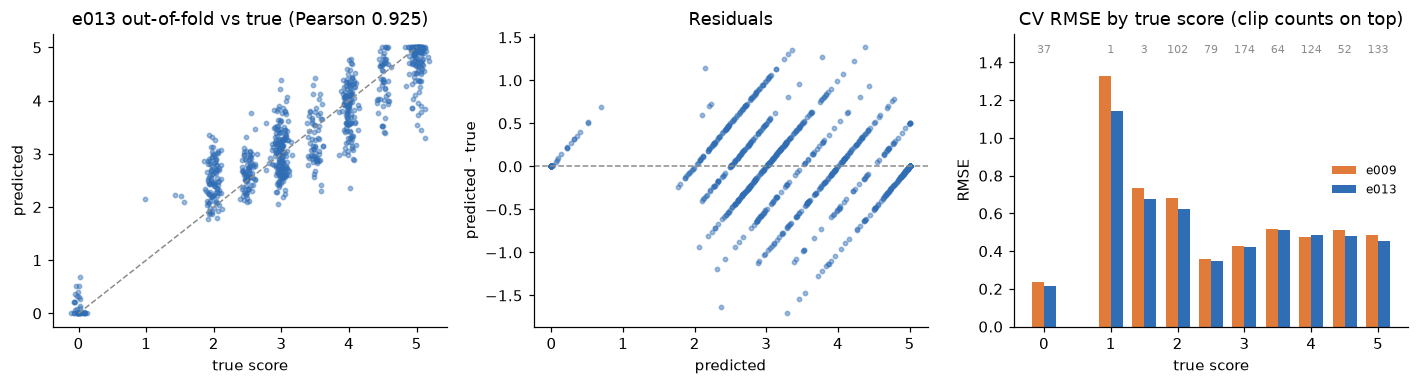

In [5]:
y, st = d13["y"], d13["stack_oof"]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
jit = np.random.default_rng(0).normal(0, 0.06, len(y))
ax[0].scatter(y + jit, st, s=8, alpha=0.45, color=BLUE)
ax[0].plot([0, 5], [0, 5], color=GREY, lw=1, ls="--")
ax[0].set(title=f"e013 out-of-fold vs true (Pearson {pearson(y, st):.3f})", xlabel="true score", ylabel="predicted")
ax[1].scatter(st, st - y, s=8, alpha=0.45, color=BLUE)
ax[1].axhline(0, color=GREY, lw=1, ls="--")
ax[1].set(title="Residuals", xlabel="predicted", ylabel="predicted - true")
w = 0.18
for off, dd, c, lab in [(-w, d09, ORANGE, "e009"), (w, d13, BLUE, "e013")]:
    g = pd.DataFrame(dict(y=dd["y"], e2=(dd["stack_oof"] - dd["y"]) ** 2)).groupby("y")
    by = g.e2.mean().pow(0.5)
    ax[2].bar(by.index + off / 2, by.values, width=w, color=c, label=lab)
for xv, n in pd.Series(y).value_counts().sort_index().items():
    ax[2].text(xv, 1.45, str(n), ha="center", fontsize=7, color=GREY)
ax[2].set(title="CV RMSE by true score (clip counts on top)", xlabel="true score", ylabel="RMSE", ylim=(0, 1.55))
ax[2].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

How the adapter improved, fold by fold (RMSE on 1-5 clips, lower is better). It beats the frozen Ridge model in
every fold, and the pseudo-labels improve it again in every fold.

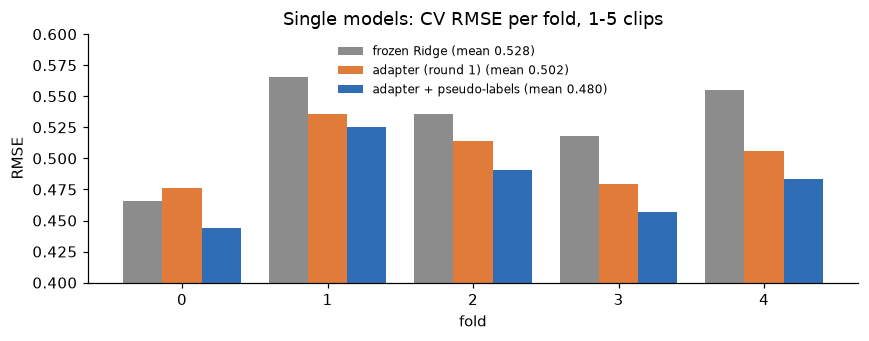

In [6]:
folds = get_folds()
nz13 = d13["y"] > 0
fold = d13["fold"]


def oof(name):
    o = pd.concat([pd.read_csv(CACHE / name / f"oof_fold{k}.csv") for k in range(5)]).set_index("filename")
    return o.loc[folds.filename, "pred"].to_numpy()


series = {"frozen Ridge": d13["P"][:, list(d13["names"]).index("frozen")],
          "adapter (round 1)": oof("adapter_whisper"), "adapter + pseudo-labels": oof("adapter3_whisper")}
fig, ax = plt.subplots(figsize=(8, 3.2))
for i, (lab, p) in enumerate(series.items()):
    r = [rmse(y[(fold == k) & nz13], p[(fold == k) & nz13]) for k in range(5)]
    ax.bar(np.arange(5) + (i - 1) * 0.27, r, width=0.27, label=f"{lab} (mean {np.mean(r):.3f})",
           color=[GREY, ORANGE, BLUE][i])
ax.set(title="Single models: CV RMSE per fold, 1-5 clips", xlabel="fold", ylabel="RMSE", ylim=(0.4, 0.6),
       xticks=range(5))
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

Which encoder layers matter? For both encoders, averaging all the layers beats any third of them on its own, and
the early layers are the weakest. So the score depends on higher-level information about words and structure,
not only on the raw sound. Newer isn't automatically better either: frozen w2v-BERT 2.0 (2023, 4.5M hours of
pre-training) was the weakest of the three.

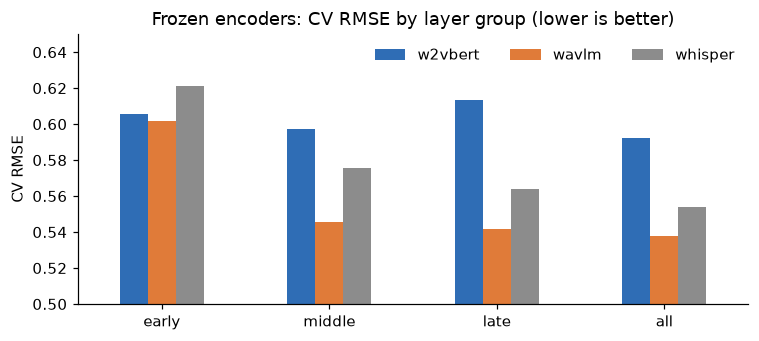

In [7]:
lg = pd.read_csv(CACHE / "e005_results.csv")
lg = lg[lg.layers != "concat"].copy()
lg["model"], lg["group"] = lg.features.str.split("_").str[0], lg.features.str.split("_").str[1]
piv = lg.pivot(index="group", columns="model", values="rmse").loc[["early", "middle", "late", "all"]]
ax = piv.plot.bar(figsize=(7, 3.2), color=[BLUE, ORANGE, GREY], rot=0)
ax.set(title="Frozen encoders: CV RMSE by layer group (lower is better)", ylabel="CV RMSE", xlabel="", ylim=(0.5, 0.65))
ax.legend(frameon=False, ncol=3)
plt.tight_layout()
plt.show()

Fine-tuning curves: validation RMSE per epoch for each fold. I fixed the number of epochs in advance (8 for WavLM,
3 for the audio LLM) and never picked an epoch by looking at these curves, so the out-of-fold scores are not
tuned on the validation data.

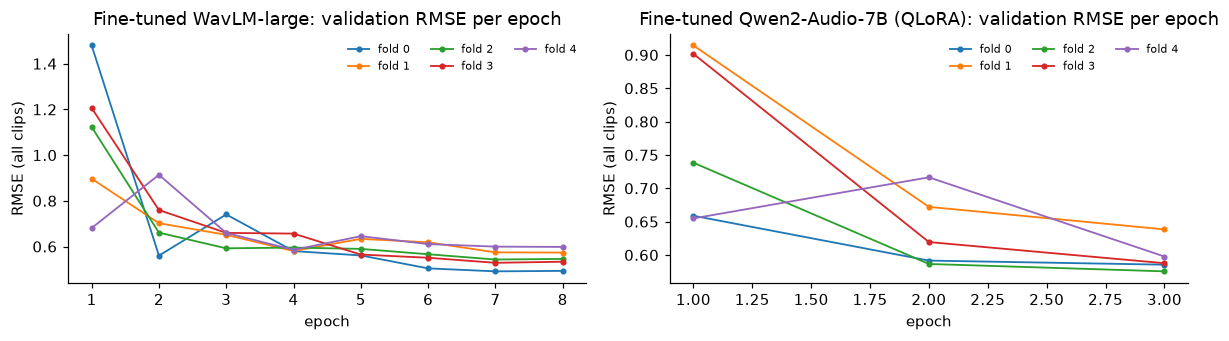

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for a, sub, title in [(ax[0], "ft", "Fine-tuned WavLM-large"), (ax[1], "alm", "Fine-tuned Qwen2-Audio-7B (QLoRA)")]:
    logs = pd.concat([pd.read_csv(CACHE / sub / f"log_fold{k}.csv") for k in range(5)])
    for k, gk in logs.groupby("fold"):
        a.plot(gk.epoch, gk.val_rmse, marker="o", ms=3, lw=1.2, label=f"fold {k}")
    a.set(title=f"{title}: validation RMSE per epoch", xlabel="epoch", ylabel="RMSE (all clips)")
    a.legend(frameon=False, ncol=3, fontsize=7)
plt.tight_layout()
plt.show()

What the transcript features show: the strongest single signals are Whisper's own word confidence and vocabulary
variety, while the direct grammar measures (LanguageTool error rate, GPT-2 likelihood, syntax) are weaker. Whisper
tends to rewrite hesitant, ungrammatical speech into clean text, so many errors never make it into the transcript.
That's why the audio models carry most of the weight.

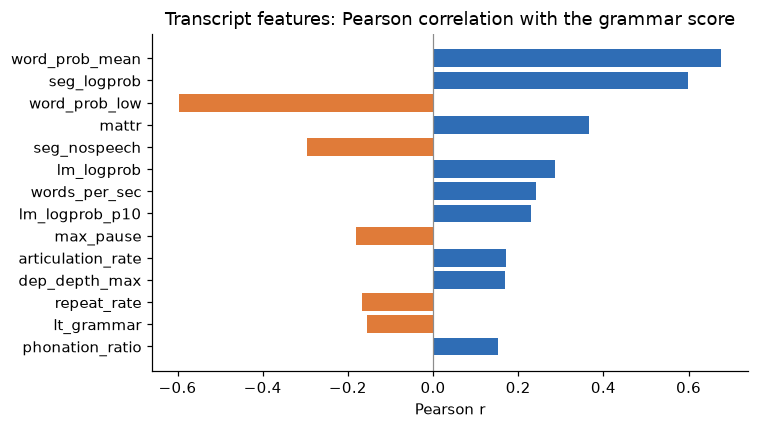

In [9]:
F = pd.read_parquet(CACHE / "feat_text.parquet")
F = F[F.split == "train"].merge(train, on="filename")
cols = [c for c in F.columns if c not in ("split", "filename", "label", "duration", "n_words", "n_sents")]
corr = pd.Series({c: np.corrcoef(F[c], F.label)[0, 1] for c in cols if F[c].std() > 0})
top = corr.reindex(corr.abs().sort_values().index[-14:])
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(top.index, top.values, color=[BLUE if v > 0 else ORANGE for v in top.values])
ax.axvline(0, color=GREY, lw=0.8)
ax.set(title="Transcript features: Pearson correlation with the grammar score", xlabel="Pearson r")
plt.tight_layout()
plt.show()

## 6. CV vs leaderboard: why two final submissions
Up to e009, the public leaderboard moved the same way as CV every time. After that, every submission with the
adapter grader scored better in CV but worse on the public leaderboard: e011 0.3742, e012 0.3790 and e013 0.3757,
against 0.3655 for e009.

  id                            what  CV RMSE (all clips)  public LB RMSE
e000                      train mean               1.2382          1.0050
e001            Whisper-tiny + Ridge               0.5679          0.4529
e002   Whisper-large + WavLM + Ridge               0.5237          0.4165
e006              + fine-tuned WavLM               0.5109          0.3985
e007           + transcript features               0.5003          0.3865
e009          + fine-tuned audio LLM               0.4916          0.3655
e011 + adapter grader (1-5 training)               0.4763          0.3742
e012                 adapter round 2               0.4739          0.3790
e013         adapter + pseudo-labels               0.4699          0.3757


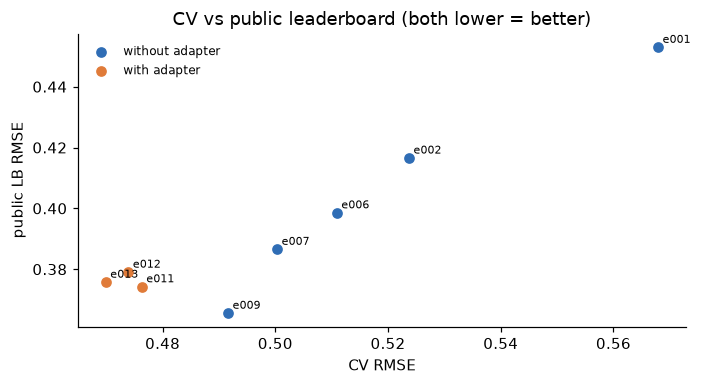

In [10]:
lb = pd.DataFrame([
    ("e000", "train mean", 1.2382, 1.0050), ("e001", "Whisper-tiny + Ridge", 0.5679, 0.4529),
    ("e002", "Whisper-large + WavLM + Ridge", 0.5237, 0.4165), ("e006", "+ fine-tuned WavLM", 0.5109, 0.3985),
    ("e007", "+ transcript features", 0.5003, 0.3865), ("e009", "+ fine-tuned audio LLM", 0.4916, 0.3655),
    ("e011", "+ adapter grader (1-5 training)", 0.4763, 0.3742), ("e012", "adapter round 2", 0.4739, 0.3790),
    ("e013", "adapter + pseudo-labels", 0.4699, 0.3757)], columns=["id", "what", "CV RMSE (all clips)", "public LB RMSE"])
print(lb.to_string(index=False))
fig, ax = plt.subplots(figsize=(6.5, 3.6))
m = lb.id != "e000"
ad = lb.id.isin(["e011", "e012", "e013"])
ax.scatter(lb[m & ~ad]["CV RMSE (all clips)"], lb[m & ~ad]["public LB RMSE"], color=BLUE, label="without adapter")
ax.scatter(lb[ad]["CV RMSE (all clips)"], lb[ad]["public LB RMSE"], color=ORANGE, label="with adapter")
for _, r in lb[m].iterrows():
    ax.annotate(r.id, (r["CV RMSE (all clips)"], r["public LB RMSE"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set(title="CV vs public leaderboard (both lower = better)", xlabel="CV RMSE", ylabel="public LB RMSE")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

Here is what I checked without using the leaderboard.

The public score is based on roughly a third of the 216 test clips. If e011 really were better, a random subset
that size would make it look this much worse 3-8% of the time. That's unlikely, but possible.

The train/test shift is real: a classifier separates train from test clips with AUC 0.84. On the 25% of train
clips that look most like test, e013 still beats e009 (0.501 vs 0.525). Re-weighting the training towards those
test-like clips didn't help, because only about 49 of the 732 clips end up carrying real weight.

I also ran a disagreement test, which needs no labels: how far each model's predictions sit from the other
models', on test compared with train. The fine-tuned models behave the same on both (ratios 0.90-0.95), but the
adapters drift away on test (1.10-1.27). So the adapter is reacting to something in the test recordings that CV
cannot see.

I tried one targeted fix, with the pass rule written down before the run: per-clip normalisation of the encoder
frames (the classic cepstral mean/variance normalisation), which removes each recording's constant microphone or
room "colour". It made CV worse on all 5 folds (0.492-0.494 vs 0.479) and on the test-like clips, and it barely
changed the drift (1.03-1.05 vs 1.07), so I did not use it.

My decision was not to tune on the public leaderboard, which uses about 70 clips while CV uses 769, and to keep one
submission for each view: e013, which is best on every CV check, and e009, which has the best public score and
doesn't depend on the adapter's less certain behaviour on test.

## 7. Error analysis, limitations, and what failed
Predictions get squeezed towards the middle: low scores come out too high and 5s too low (see the RMSE by true
score plot). Scores 1.0-1.5 have only 4 training clips, so the model has almost no examples of the bottom of the
scale.

Short clips are harder. On train clips under 50 s, which are like most of the test set, e013's error is 0.545
against 0.456 on longer clips. Training the adapter on variable-length crops with the clip length as an input did
not change this, so short clips are probably harder recordings or speakers rather than a length mismatch.

ASR hides grammar errors. Whisper cleans them up, so the transcript-based grammar features are weak. The audio
models don't have that problem, but they also pick up fluency and confidence, not only grammar.

The data is small, about 585 training clips per fold. Fine-tuning a large model on its own does not beat the
frozen features (fine-tuned WavLM 0.550 and the audio LLM 0.597, against 0.521 for frozen Ridge); both are useful
only as extra opinions in the stack.

Things I tried and dropped (all measured; details in `docs/decisions.md`):

| Idea | Result |
|---|---|
| SVR instead of Ridge | 0.523 vs 0.524, no gain |
| Adding frozen w2v-BERT 2.0 | 0.520 vs 0.524, within noise |
| Zero-shot Qwen2-Audio rubric judge | correlation with labels only 0.43; +0.0007 in the stack |
| WavLM adapter | weight 0 in the stack |
| Short-clip-aware adapter (round 2) | +0.002, bootstrap interval includes 0 |
| Importance-weighted stack | worse on test-like clips |
| Per-clip normalised adapter (round 4) | worse on all 5 folds |

## 8. Reproduce
```
python src/audit.py                       # data checks
python src/cv.py                          # fixed folds -> cache/folds.csv
# GPU stages on Kaggle T4 x2 (one worker per GPU); each builder writes kaggle/<stage>/, then:
#   kaggle kernels push -p kaggle/<stage> --accelerator NvidiaTeslaT4
#   kaggle kernels output <kernel> -p cache/<dir>
kaggle/build_embed.sh                     # frozen Whisper/WavLM embeddings -> cache/emb
kaggle/build_transcribe.sh                # transcripts -> cache/transcripts.jsonl
kaggle/build_finetune.sh                  # fine-tuned WavLM -> cache/ft
kaggle/build_ft_alm.sh                    # fine-tuned Qwen2-Audio -> cache/alm
kaggle/build_adapter.sh                   # adapter graders, round 1 -> cache/adapter_whisper, cache/adapter_wavlm
python src/features.py                    # transcript features (needs Java for LanguageTool)
python src/final.py --exp e011 --no-judge --nz --drop adapter2_whisper,adapter3_whisper,adapter4mean_whisper,adapter4meanvar_whisper
python src/pseudo.py                      # leakage-free pseudo-labels from the e011 teacher
kaggle/build_adapter3.sh                  # pseudo-labelled adapter -> cache/adapter3_whisper
# the two final submissions:
python src/final.py --exp e013 --no-judge --nz --drop adapter_whisper,adapter2_whisper,adapter4mean_whisper,adapter4meanvar_whisper
python src/final.py --exp e009 --no-judge --drop adapter_whisper,adapter_wavlm,adapter2_whisper,adapter3_whisper,adapter4mean_whisper,adapter4meanvar_whisper
```
I re-ran both final commands from the cached model outputs and they give back the submitted files exactly.
The heavy stages write checkpoints, so a dropped Kaggle session can resume,
and this notebook only reads the cached results in `cache/`.